In [ ]:
import pandas as pd

meta = pd.read_csv("../data/raw/metadata.csv")
print(meta.shape)
print(list(meta.colSumns))
meta.head()

(1636, 32)
['building_id', 'site_id', 'building_id_kaggle', 'site_id_kaggle', 'primaryspaceusage', 'sub_primaryspaceusage', 'sqm', 'sqft', 'lat', 'lng', 'timezone', 'electricity', 'hotwater', 'chilledwater', 'steam', 'water', 'irrigation', 'solar', 'gas', 'industry', 'subindustry', 'heatingtype', 'yearbuilt', 'date_opened', 'numberoffloors', 'occupants', 'energystarscore', 'eui', 'site_eui', 'source_eui', 'leed_level', 'rating']


,building_id,site_id,building_id_kaggle,site_id_kaggle,primaryspaceusage,sub_primaryspaceusage,sqm,sqft,lat,lng,...,yearbuilt,date_opened,numberoffloors,occupants,energystarscore,eui,site_eui,source_eui,leed_level,rating
0,Panther_lodging_Dean,Panther,NaN,0.0,Lodging/residential,Residence Hall,508.8,5477.0,28.517689,-81.379039,...,1989.0,NaN,NaN,NaN,NaN,271,NaN,NaN,NaN,NaN
1,Panther_lodging_Shelia,Panther,NaN,0.0,Lodging/residential,Residence Hall,929.0,10000.0,28.517689,-81.379039,...,1992.0,NaN,NaN,NaN,NaN,62,NaN,NaN,NaN,NaN
2,Panther_lodging_Ricky,Panther,NaN,0.0,Lodging/residential,Residence Hall,483.1,5200.0,28.517689,-81.379039,...,2016.0,NaN,NaN,NaN,NaN,534,NaN,NaN,NaN,NaN
3,Panther_education_Rosalie,Panther,0.0,0.0,Education,Research,690.5,7432.0,28.517689,-81.379039,...,2008.0,NaN,NaN,NaN,NaN,276,NaN,NaN,NaN,NaN
4,Panther_education_Misty,Panther,1.0,0.0,Education,Research,252.7,2720.0,28.517689,-81.379039,...,2004.0,NaN,NaN,NaN,NaN,375,NaN,NaN,NaN,NaN


In [2]:
elec = pd.read_csv("../data/raw/electricity.csv", index_col=0, parse_dates=True)
print(elec.shape)
print(elec.index.min(), "to", elec.index.max())
elec.iloc[:5, :5]

(17544, 1578)
2016-01-01 00:00:00 to 2017-12-31 23:00:00


,Panther_parking_Lorriane,Panther_lodging_Cora,Panther_office_Hannah,Panther_lodging_Hattie,Panther_education_Teofila
timestamp,,,,,
2016-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0
2016-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0


In [3]:
weather = pd.read_csv("../data/raw/weather.csv")
print(weather.shape)
print(list(weather.columns))
weather.head()

(331166, 10)
['timestamp', 'site_id', 'airTemperature', 'cloudCoverage', 'dewTemperature', 'precipDepth1HR', 'precipDepth6HR', 'seaLvlPressure', 'windDirection', 'windSpeed']


,timestamp,site_id,airTemperature,cloudCoverage,dewTemperature,precipDepth1HR,precipDepth6HR,seaLvlPressure,windDirection,windSpeed
0,2016-01-01 00:00:00,Panther,19.4,NaN,19.4,0.0,NaN,NaN,0.0,0.0
1,2016-01-01 01:00:00,Panther,21.1,6.0,21.1,-1.0,NaN,1019.4,0.0,0.0
2,2016-01-01 02:00:00,Panther,21.1,NaN,21.1,0.0,NaN,1018.8,210.0,1.5
3,2016-01-01 03:00:00,Panther,20.6,NaN,20.0,0.0,NaN,1018.1,0.0,0.0
4,2016-01-01 04:00:00,Panther,21.1,NaN,20.6,0.0,NaN,1019.0,290.0,1.5


In [4]:
meta_e = meta[meta["building_id"].isin(elec.columns)]
print(len(meta_e), "buildings with electricity")
print(meta_e["primaryspaceusage"].value_counts())
meta_e.groupby(["primaryspaceusage", "sub_primaryspaceusage"]).size().sort_values(ascending=False).head(30)

1578 buildings with electricity
primaryspaceusage
Education                        604
Office                           296
Entertainment/public assembly    203
Public services                  166
Lodging/residential              149
Healthcare                        27
Other                             26
Parking                           23
Warehouse/storage                 14
Retail                            11
Manufacturing/industrial          11
Services                           9
Technology/science                 7
Food sales and service             6
Utility                            4
Religious worship                  3
Name: count, dtype: int64


primaryspaceusage              sub_primaryspaceusage              
Office                         Office                                 295
Education                      College Classroom                      131
                               College Laboratory                     116
                               K-12 School                            109
Lodging/residential            Dormitory                               91
Education                      Primary/Secondary Classroom             84
                               Education                               67
Public services                Library                                 54
Entertainment/public assembly  Other - Recreation                      42
Public services                Fire Station                            34
Education                      Research                                29
                               Classroom                               27
Entertainment/public assembly  Community Cent

In [5]:
quality = pd.DataFrame({
    "missing_pct": elec.isna().mean() * 100,
    "zero_pct": (elec == 0).mean() * 100,
})
quality = quality.join(
    meta.set_index("building_id")[["site_id", "primaryspaceusage", "sub_primaryspaceusage", "sqm"]]
)
print(quality.groupby("primaryspaceusage")[["missing_pct", "zero_pct"]].median().round(1))
print(quality["site_id"].value_counts())

                               missing_pct  zero_pct
primaryspaceusage                                   
Education                              0.1       0.0
Entertainment/public assembly          0.2       0.1
Food sales and service                 0.0       1.3
Healthcare                             0.0       0.6
Lodging/residential                    0.1       0.0
Manufacturing/industrial               0.0       0.0
Office                                 0.0       0.1
Other                                  0.9       0.8
Parking                                0.1       0.2
Public services                        0.4       0.0
Religious worship                      0.3       0.0
Retail                                 0.1      11.0
Services                               0.1       1.6
Technology/science                     0.2       0.0
Utility                                4.3       0.0
Warehouse/storage                      0.4       0.0
site_id
Rat         305
Hog         152
Lamb  

In [6]:
subs = ["Office", "College Classroom", "College Laboratory", "Dormitory", "Library"]
quality.index.name = "building_id"
good = quality[(quality["missing_pct"] < 1) & (quality["zero_pct"] < 1)].reset_index()
good = good[good["sub_primaryspaceusage"].isin(subs)]

counts = good.groupby(["site_id", "sub_primaryspaceusage"]).size().unstack(fill_value=0)
for s in subs:
    if s not in counts.columns:
        counts[s] = 0
counts = counts[subs]
print("Sites with all five types:")
print(counts[(counts > 0).all(axis=1)])

Sites with all five types:
sub_primaryspaceusage  Office  College Classroom  College Laboratory  \
site_id                                                                
Fox                        22                 22                  25   
Hog                        63                  3                  14   
Peacock                     7                  5                   6   
Robin                      16                  3                  19   

sub_primaryspaceusage  Dormitory  Library  
site_id                                    
Fox                           12        5  
Hog                            9        5  
Peacock                       11        1  
Robin                         10        2  


In [7]:
cols = [c for c in ["site_id", "lat", "lng", "timezone"] if c in meta.columns]
print(meta[meta["site_id"] == "Fox"][cols].drop_duplicates())

fox = good[good["site_id"] == "Fox"]
for s in subs:
    print("\n==", s, "==")
    print(
        fox[fox["sub_primaryspaceusage"] == s]
        .sort_values("sqm")[["building_id", "sqm", "missing_pct", "zero_pct"]]
        .round(2)
        .head(12)
        .to_string(index=False)
    )

    site_id        lat        lng     timezone
188     Fox  33.424425 -111.92814  US/Mountain

== Office ==
         building_id    sqm  missing_pct  zero_pct
  Fox_office_Clayton  488.5         0.01      0.01
    Fox_office_Molly  576.3         0.02      0.08
   Fox_office_Sheila  901.4         0.02      0.02
  Fox_office_Susanne  941.6         0.01      0.01
 Fox_office_Berniece 2173.2         0.02      0.10
Fox_office_Margarita 2187.8         0.02      0.97
   Fox_office_Easter 2766.5         0.59      0.03
   Fox_office_Rowena 3132.0         0.01      0.13
   Fox_office_Brandy 3921.8         0.01      0.05
  Fox_office_Bernard 4182.2         0.01      0.01
   Fox_office_Karima 4806.1         0.01      0.01
    Fox_office_Vicki 6580.5         0.01      0.06

== College Classroom ==
            building_id    sqm  missing_pct  zero_pct
Fox_education_Marcelina  400.8         0.13      0.40
    Fox_education_Elois  695.0         0.02      0.03
    Fox_education_Ashli  864.8         0.0

In [9]:
picks = {}
for s in subs:
    c = fox[fox["sub_primaryspaceusage"] == s].copy()
    c["dist"] = (c["sqm"] - c["sqm"].median()).abs()
    c["bad"] = c["missing_pct"] + c["zero_pct"]
    best = c.sort_values("dist").head(3).sort_values("bad").iloc[0]
    picks[s] = best
suggested = pd.DataFrame(picks).T[["building_id", "sqm", "missing_pct", "zero_pct"]]
print(suggested.to_string())

                             building_id     sqm missing_pct zero_pct
Office                 Fox_office_Karima  4806.1      0.0057   0.0057
College Classroom   Fox_education_Claire  8145.1      0.0057   0.0057
College Laboratory  Fox_education_Tamika  8339.9      0.0057   0.0399
Dormitory            Fox_lodging_Wallace  5885.2      0.0171   0.0057
Library                  Fox_public_Bart  9407.5      0.0114   0.0114


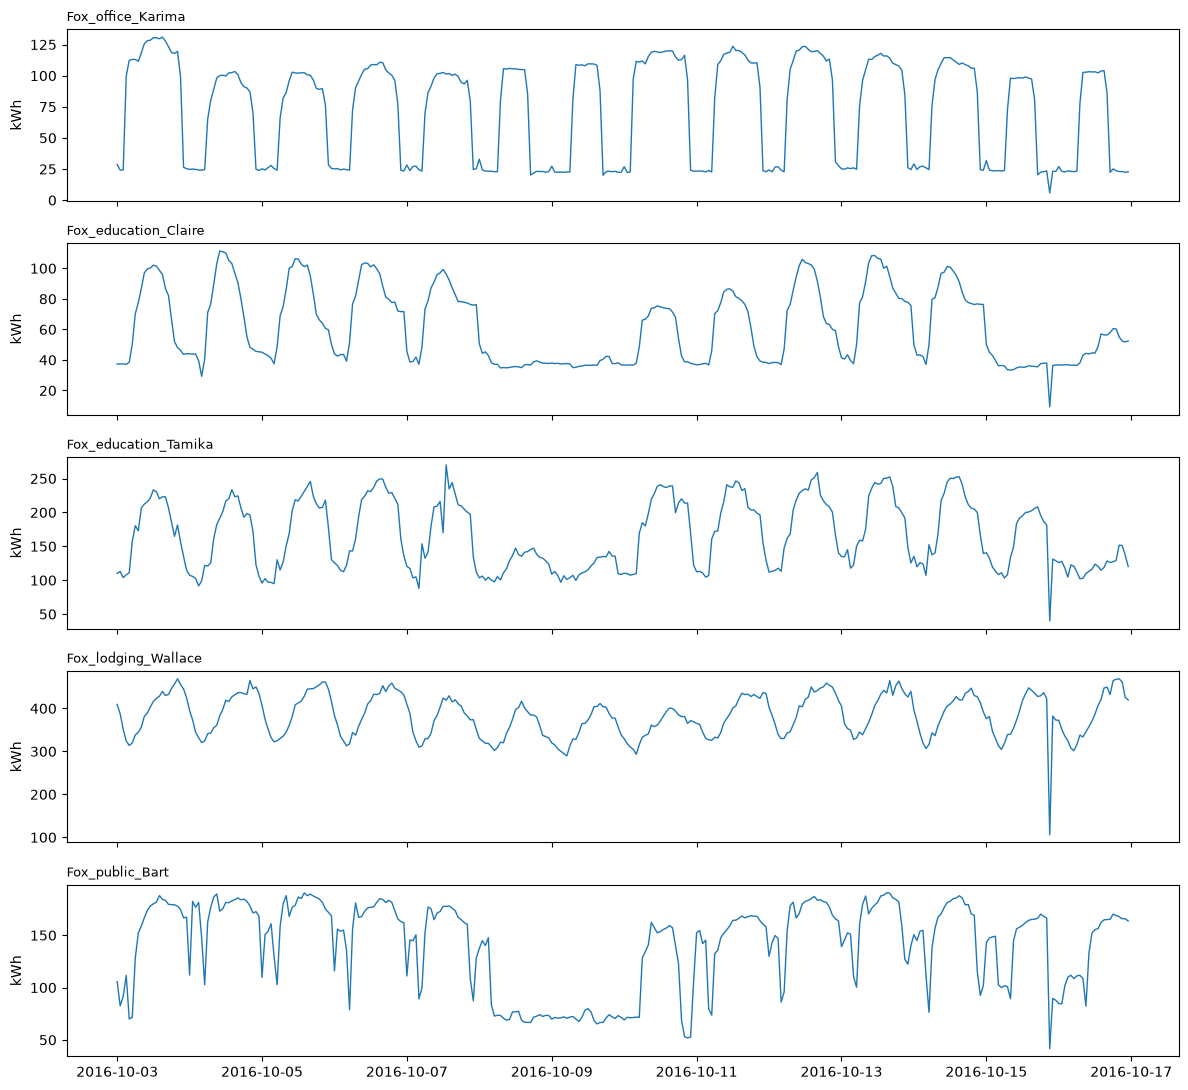

In [10]:
import matplotlib.pyplot as plt

chosen = suggested["building_id"].tolist()
week = elec.loc["2016-10-03":"2016-10-16", chosen]

fig, axes = plt.subplots(len(chosen), 1, figsize=(12, 11), sharex=True)
for ax, b in zip(axes, chosen):
    ax.plot(week.index, week[b], lw=1)
    ax.set_title(b, fontsize=9, loc="left")
    ax.set_ylabel("kWh")
plt.tight_layout()
plt.show()

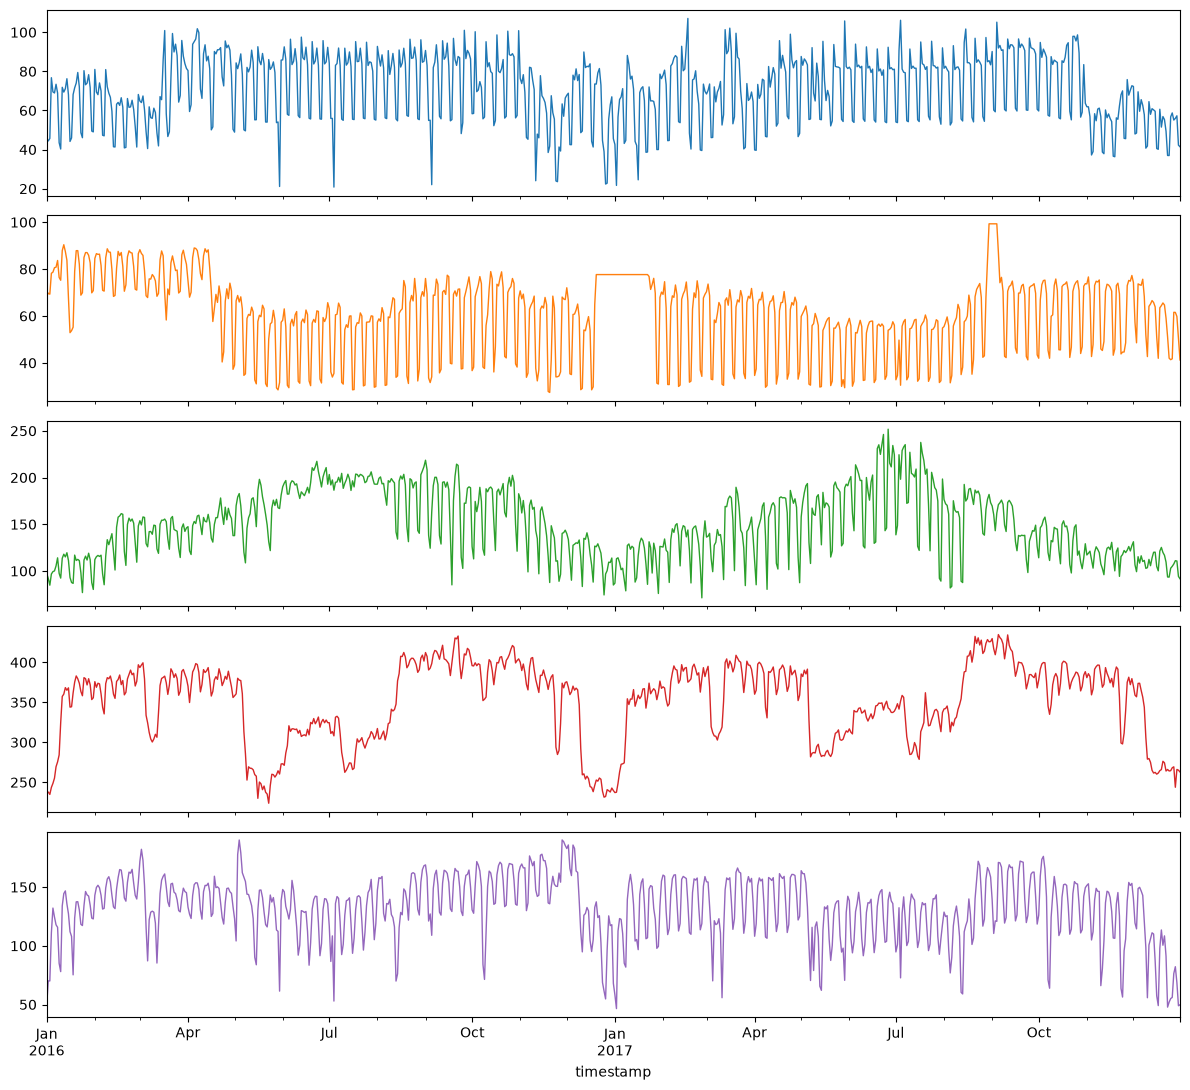

In [11]:
daily = elec[chosen].resample("D").mean()
daily.plot(subplots=True, figsize=(12, 11), legend=False, lw=1)
plt.tight_layout()
plt.show()

In [12]:
ratio = elec[chosen] / elec[chosen].rolling(24 * 7, center=True, min_periods=24).median()
simultaneous = (ratio < 0.5).sum(axis=1) >= 4
print(simultaneous.sum(), "hours where 4+ buildings drop below 50% of normal")
print(simultaneous[simultaneous].index[:15])

19 hours where 4+ buildings drop below 50% of normal
DatetimeIndex(['2016-05-02 03:00:00', '2016-05-09 04:00:00',
               '2016-05-16 02:00:00', '2016-05-16 03:00:00',
               '2016-05-23 01:00:00', '2016-05-23 03:00:00',
               '2016-05-23 04:00:00', '2016-07-04 04:00:00',
               '2016-07-11 03:00:00', '2016-08-15 03:00:00',
               '2016-10-15 21:00:00', '2016-11-06 14:00:00',
               '2017-04-08 02:00:00', '2017-04-09 00:00:00',
               '2017-04-09 01:00:00'],
              dtype='datetime64[us]', name='timestamp', freq=None)


In [13]:
mapping = {"Office": "B04", "College Classroom": "B01", "College Laboratory": "B05",
           "Dormitory": "B03", "Library": "B02"}
sel = suggested.reset_index().rename(columns={"index": "bdg2_subtype"})
sel["campus_building"] = sel["bdg2_subtype"].map(mapping)
sel = sel[["campus_building", "bdg2_subtype", "building_id", "sqm"]].sort_values("campus_building")
sel.to_csv("../config/building_mapping.csv", index=False)
sel

,campus_building,bdg2_subtype,building_id,sqm
1,B01,College Classroom,Fox_education_Claire,8145.1
4,B02,Library,Fox_public_Bart,9407.5
3,B03,Dormitory,Fox_lodging_Wallace,5885.2
0,B04,Office,Fox_office_Karima,4806.1
2,B05,College Laboratory,Fox_education_Tamika,8339.9


In [14]:
flat = elec[chosen].diff().eq(0).rolling(24).sum().ge(24)
for b in chosen:
    f = flat[b]
    print(b, int(f.sum()), "hours in flat runs;",
          f[f].index.min(), "to", f[f].index.max())

Fox_office_Karima 0 hours in flat runs; NaT to NaT
Fox_education_Claire 978 hours in flat runs; 2016-11-20 13:00:00 to 2017-09-05 07:00:00
Fox_education_Tamika 0 hours in flat runs; NaT to NaT
Fox_lodging_Wallace 0 hours in flat runs; NaT to NaT
Fox_public_Bart 0 hours in flat runs; NaT to NaT


In [15]:
cands = fox[fox["sub_primaryspaceusage"] == "College Classroom"]["building_id"].tolist()
flat_hours = elec[cands].diff().eq(0).rolling(24).sum().ge(24).sum()
res = (pd.DataFrame({"flat_hours": flat_hours})
       .join(fox.set_index("building_id")[["sqm", "missing_pct", "zero_pct"]])
       .sort_values(["flat_hours", "missing_pct"]))
print(res.round(2).head(12).to_string())

                        flat_hours      sqm  missing_pct  zero_pct
Fox_education_Ollie              0   6698.5         0.01      0.01
Fox_education_Burton             0   7028.1         0.01      0.03
Fox_education_Nilda              0  10371.2         0.01      0.01
Fox_education_Kim                0   5782.1         0.01      0.03
Fox_education_Dewayne            0   8892.4         0.01      0.08
Fox_education_Ashli              0    864.8         0.01      0.01
Fox_education_Long               0  12733.7         0.01      0.01
Fox_education_Louie              0  16645.2         0.01      0.01
Fox_education_Eddy               0  13015.0         0.01      0.01
Fox_education_Leona              0  26286.5         0.01      0.01
Fox_education_Sterling           0   4106.6         0.02      0.02
Fox_education_Elois              0    695.0         0.02      0.03


campus_building       bdg2_subtype          building_id     sqm
            B01  College Classroom Fox_education_Burton  7028.1
            B02            Library      Fox_public_Bart  9407.5
            B03          Dormitory  Fox_lodging_Wallace  5885.2
            B04             Office    Fox_office_Karima  4806.1
            B05 College Laboratory Fox_education_Tamika  8339.9


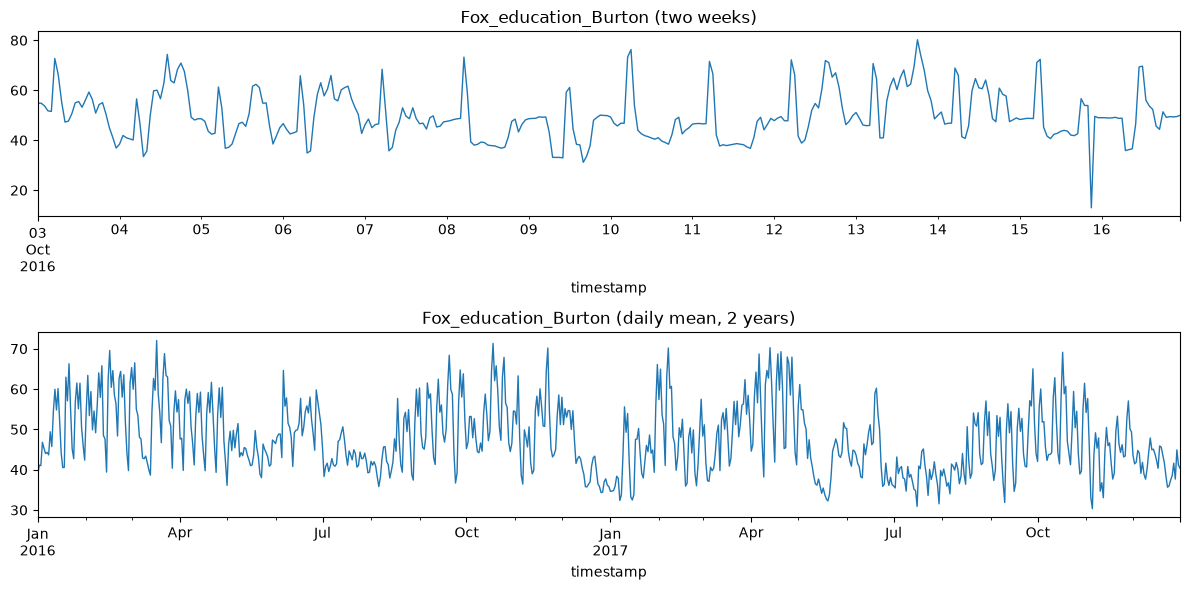

In [16]:
row = fox[fox["building_id"] == "Fox_education_Burton"].iloc[0]
suggested.loc["College Classroom"] = [row["building_id"], row["sqm"], row["missing_pct"], row["zero_pct"]]
chosen = suggested["building_id"].tolist()

sel = suggested.reset_index().rename(columns={"index": "bdg2_subtype"})
sel["campus_building"] = sel["bdg2_subtype"].map(mapping)
sel = sel[["campus_building", "bdg2_subtype", "building_id", "sqm"]].sort_values("campus_building")
sel.to_csv("../config/building_mapping.csv", index=False)
print(sel.to_string(index=False))

b = "Fox_education_Burton"
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
elec.loc["2016-10-03":"2016-10-16", b].plot(ax=ax[0], lw=1, title=b + " (two weeks)")
elec[b].resample("D").mean().plot(ax=ax[1], lw=1, title=b + " (daily mean, 2 years)")
plt.tight_layout()
plt.show()